## Configurar o uso da GPU (Nvidia e AMD), carregar o modelo e preparar os caminhos dos arquivos

In [2]:
import os
import torch
import cv2
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt
from ultralytics import YOLO

# 1. Detecção adaptativa de hardware
def definir_dispositivo_teste():
    if torch.cuda.is_available():
        print("GPU NVIDIA Detectada! Testes rodarão via CUDA.")
        return "cuda:0", False
    try:
        import torch_directml
        dml_device = torch_directml.device()
        print(f"GPU AMD/Intel Detectada! Testes rodarão via DirectML ({dml_device}).")
        return dml_device, True
    except Exception as e:
        print(f"Nota sobre AMD: DirectML não inicializado. Motivo: {e}")
        return "cpu", False

DISPOSITIVO_TESTE, EH_AMD = definir_dispositivo_teste()

# ==============================================================================
# PAINEL DE CONFIGURAÇÃO DO DATASET ATIVO
# ==============================================================================
DATASET_ATIVO = "placas"  # Altere para "placas" ou "ingredientes"

CONFIG_DATASETS = {
    "ingredientes": {
        "classe_alvo": "tomato",       # Altere para a classe real do seu dataset
        "pasta_teste": "../tests/ingredientes"
    },
    "placas": {
        "classe_alvo": "do_not_enter", # Classe alvo padrão de placas
        "pasta_teste": "../tests/placas"
    }
}

if DATASET_ATIVO not in CONFIG_DATASETS:
    raise ValueError(f"Dataset '{DATASET_ATIVO}' não foi configurado em CONFIG_DATASETS.")

ARQUIVO_CONFIG = f"../data_{DATASET_ATIVO}.yaml"
PASTA_TESTE = CONFIG_DATASETS[DATASET_ATIVO]["pasta_teste"]
MODELO_PATH = "../models/yolov8s.onnx" 

print(f"Carregando o modelo baseline: {MODELO_PATH}")

# 2. Correção automática de metadados ONNX
try:
    model_proto = onnx.load(MODELO_PATH)
    if model_proto.ir_version > 13:
        print(f"Ajustando versão IR {model_proto.ir_version} para IR 13...")
        model_proto.ir_version = 13
        onnx.save(model_proto, MODELO_PATH)
        print("Arquivo ONNX atualizado com sucesso!")
except Exception as e:
    print(f"Nota: Metadados ONNX preservados. Razão: {e}")

# 3. Carregamento do mapeamento de classes dinâmico
NOMES_CLASSES_DINAMICO = {}

if EH_AMD:
    print("Configurando ambiente ONNX Runtime puro para GPU AMD...")
    ort_session = ort.InferenceSession(MODELO_PATH, providers=['CPUExecutionProvider'])
    meta = ort_session.get_modelmeta().custom_metadata_map
    if 'names' in meta:
        NOMES_CLASSES_DINAMICO = eval(meta['names'])
    else:
        print("Aviso: Não foi possível ler as classes dos metadados do ONNX automaticamente.")
else:
    model = YOLO(MODELO_PATH)
    model.to(DISPOSITIVO_TESTE)
    NOMES_CLASSES_DINAMICO = model.names
    print(f"Modelo carregado com sucesso no dispositivo: {DISPOSITIVO_TESTE}")

print(f"Mapeamento detectado: {list(NOMES_CLASSES_DINAMICO.values())[:5]}... ({len(NOMES_CLASSES_DINAMICO)} classes total).")


GPU AMD/Intel Detectada! Testes rodarão via DirectML (privateuseone:0).
Carregando o modelo baseline: ../models/yolov8s.onnx
Configurando ambiente ONNX Runtime puro para GPU AMD...
Mapeamento detectado: ['person', 'bicycle', 'car', 'motorcycle', 'airplane']... (80 classes total).


## TESTE 1 – Inferência em uma única Imagem Individual

Total de imagens na pasta: 48
--- Inferência (Imagem Índice 10): ../tests/placas\larangan-belok-kiri--72-_jpg.rf.9aa2721998797689e1f6487784fac9cb.jpg ---

--- DETECÇÕES ESTRUTURADAS ---
Classe: clock | Confiança: 0.48 | BBox: [138, 87, 451, 433]


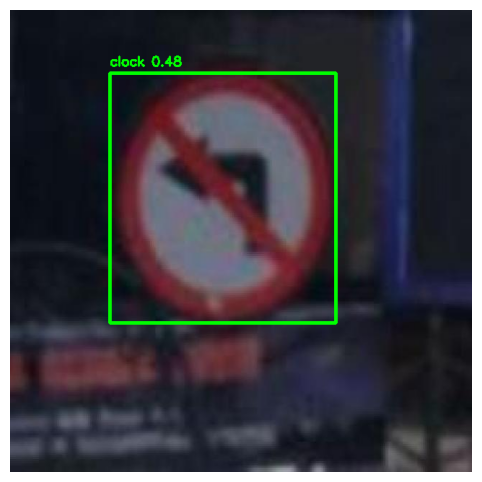

In [4]:
import numpy as np
import glob
import random

# 1. Busca dinâmica de imagens na pasta ativa
padroes_imagens = [f"{PASTA_TESTE}/*.jpg", f"{PASTA_TESTE}/*.jpeg", f"{PASTA_TESTE}/*.png"]
imagens_encontradas = []
for padrao in padroes_imagens:
    imagens_encontradas.extend(glob.glob(padrao))
imagens_encontradas = sorted(imagens_encontradas)

if not imagens_encontradas:
    raise FileNotFoundError(f"Nenhuma imagem válida encontrada na pasta: '{PASTA_TESTE}'")

# ==============================================================================
# PAINEL DE CONTROLE DE SELEÇÃO DA IMAGEM E FILTRAGEM (AJUSTE AQUI)
# ==============================================================================
MODO_ALEATORIO = False  # Mude para True para testar fotos surpresa
INDICE_DA_IMAGEM = 10    # Altere o número (0, 1, 2...) para navegar pelas fotos da pasta

CONF_THRESHOLD = 0.40   # Confiança mínima aceitável
IOU_THRESHOLD = 0.45    # Limiar do NMS (valores menores eliminam mais sobreposições)
# ==============================================================================

if MODO_ALEATORIO:
    IMAGEM_TESTE = random.choice(imagens_encontradas)
    print(f"🎲 Modo Aleatório Ativo!")
else:
    INDICE_DA_IMAGEM = max(0, min(INDICE_DA_IMAGEM, len(imagens_encontradas) - 1))
    IMAGEM_TESTE = imagens_encontradas[INDICE_DA_IMAGEM]

print(f"Total de imagens na pasta: {len(imagens_encontradas)}")
print(f"--- Inferência (Imagem Índice {imagens_encontradas.index(IMAGEM_TESTE)}): {IMAGEM_TESTE} ---")

caixas_detectadas_geral = []
img_bgr = cv2.imread(IMAGEM_TESTE)
h_orig, w_orig = img_bgr.shape[:2]

if EH_AMD:
    # Fluxo AMD com pós-processamento NMS via OpenCV
    img_resized = cv2.resize(img_bgr, (640, 640))
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    input_data = np.expand_dims(img_rgb.transpose(2, 0, 1), axis=0).astype(np.float32) / 255.0
    
    input_name = ort_session.get_inputs()[0].name
    outputs = ort_session.run(None, {input_name: input_data})
    predictions = np.squeeze(outputs[0]).T  
    
    boxes, confidences, class_ids = [], [], []
    
    for pred in predictions:
        x_center, y_center, width, height = pred[:4]
        scores = pred[4:]
        cls_id = int(np.argmax(scores))
        conf = float(scores[cls_id])
        
        if conf > CONF_THRESHOLD:
            x_min = int((x_center - width / 2) * (w_orig / 640.0))
            y_min = int((y_center - height / 2) * (h_orig / 640.0))
            w_box = int(width * (w_orig / 640.0))
            h_box = int(height * (h_orig / 640.0))
            
            boxes.append([x_min, y_min, w_box, h_box])
            confidences.append(conf)
            class_ids.append(cls_id)
            
    indices_validos = cv2.dnn.NMSBoxes(boxes, confidences, CONF_THRESHOLD, IOU_THRESHOLD)
    if len(indices_validos) > 0:
        for i in indices_validos.flatten():
            x_min, y_min, w_box, h_box = boxes[i]
            caixas_detectadas_geral.append((x_min, y_min, x_min + w_box, y_min + h_box, confidences[i], class_ids[i]))
else:
    # Fluxo NVIDIA/CPU com NMS nativo da Ultralytics
    with torch.inference_mode():
        resultados = model(IMAGEM_TESTE, imgsz=640, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, device=DISPOSITIVO_TESTE)
    for result in resultados:
        for box in result.boxes:
            conf = float(box.conf)
            cls_id = int(box.cls)
            x_min, y_min, x_max, y_max = box.xyxy.tolist()[0]
            caixas_detectadas_geral.append((int(x_min), int(y_min), int(x_max), int(y_max), conf, cls_id))

# Renderização gráfica final
print("\n--- DETECÇÕES ESTRUTURADAS ---")
imagem_rgb_output = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

for x_min, y_min, x_max, y_max, conf, cls_id in caixas_detectadas_geral:
    nome_classe = NOMES_CLASSES_DINAMICO.get(cls_id, f"Classe_{cls_id}")
    print(f"Classe: {nome_classe} | Confiança: {conf:.2f} | BBox: [{x_min}, {y_min}, {x_max}, {y_max}]")
    
    cv2.rectangle(imagem_rgb_output, (x_min, y_min), (x_max, y_max), (0, 255, 0), 3)
    texto_tag = f"{nome_classe} {conf:.2f}"
    cv2.putText(imagem_rgb_output, texto_tag, (x_min, max(y_min - 10, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

if not caixas_detectadas_geral:
    print(f"Nenhum objeto detectado acima de {CONF_THRESHOLD:.2f}.")

plt.figure(figsize=(10, 6))
plt.imshow(imagem_rgb_output)
plt.axis('off')
plt.show()


## TESTE 2 – Métricas Isoladas de uma Classe Específica

In [5]:
import numpy as np

# 1. Se o NumPy instalado removeu o 'trapz', clonamos a nova função 'trapezoid' para o nome antigo
if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid
# =================================================================

# 2. Definimos qual dispositivo o validador usará: se for AMD, forçamos 'cpu' para evitar crash de tensores
DISPOSITIVO_VALIDACAO = 'cpu' if EH_AMD else DISPOSITIVO_TESTE

print(f"Iniciando validação oficial na classe alvo utilizando: {DISPOSITIVO_VALIDACAO}")

# 3. Executa a validação oficial do YOLO no dataset ativo (forçando CPU para AMD)
if EH_AMD:
    from ultralytics import YOLO
    # Recarrega temporariamente o modelo base em CPU para permitir o uso da função .val()
    model_val = YOLO(MODELO_PATH.replace(".onnx", ".pt") if MODELO_PATH.endswith(".onnx") else MODELO_PATH)
    metrics = model_val.val(data=ARQUIVO_CONFIG, split="val", plots=False, device=DISPOSITIVO_VALIDACAO)
else:
    metrics = model.val(data=ARQUIVO_CONFIG, split="val", plots=False, device=DISPOSITIVO_VALIDACAO)

# 4. === AJUSTE DE CLASSE ALVO (Escolha qual deseja inspecionar aqui) ===
CLASSE_ALVO = CONFIG_DATASETS[DATASET_ATIVO]["classe_alvo"]

# Extraímos o mapeamento de classes interno e real gerado pelo validador.
# Isso impede o crash de tamanho (ValueError) caso o modelo ainda carregue 80 classes do COCO.
mapeamento_real_validacao = metrics.names

# Descobre o ID correspondente ao nome da classe alvo usando a saída real do validador
id_classe_alvo = None
for idx, name in mapeamento_real_validacao.items():
    if name == CLASSE_ALVO:
        id_classe_alvo = int(idx)
        break

if id_classe_alvo is not None:
    # Tratamento dinâmico para extrair o mAP50 por classe (.ap50)
    lista_ap50 = metrics.box.ap50() if callable(getattr(metrics.box, "ap50", None)) else metrics.box.ap50
    
    # Coleta os dados de dentro do submódulo '.box' usando o ID alinhado do validador
    precision_classe = metrics.box.p[id_classe_alvo]      
    recall_classe = metrics.box.r[id_classe_alvo]         
    map50_classe = lista_ap50[id_classe_alvo]     
    
    print(f"\n=== MÉTRICAS ISOLADAS PARA A CLASSE: '{CLASSE_ALVO.upper()}' ===")
    print(f"Precisão (Precision): {precision_classe:.4f}")
    print(f"Revocação (Recall):    {recall_classe:.4f}")
    print(f"mAP50 da Classe:       {map50_classe:.4f}")
else:
    print(f"Classe '{CLASSE_ALVO}' não encontrada no mapeamento real do processo de validação.")


Iniciando validação oficial na classe alvo utilizando: cpu
Ultralytics 8.3.0  Python-3.12.10 torch-2.4.1+cpu CPU (Intel Core(TM) i5-3330 3.00GHz)
YOLOv8s summary (fused): 168 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs


val: Scanning E:\projeto dataset\road signs.v2\valid\labels.cache... 488 images, 0 backgrounds, 0 corrupt: 100%|██████████| 488/488 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 31/31 [05:54<00:00, 11.44s/it]


                   all        488        529    0.00661      0.117    0.00455    0.00246
               bicycle         30         30   0.000866     0.0333   0.000574   5.74e-05
                   car         30         30          0          0          0          0
            motorcycle         30         34     0.0103      0.265    0.00664    0.00491
              airplane         30         31     0.0123     0.0645    0.00744    0.00468
                   bus         30         30    0.00721      0.233    0.00462    0.00205
                 train         30         30    0.00339      0.133    0.00241     0.0015
                 truck         30         47    0.00378      0.106    0.00219    0.00104
                  boat          9          9    0.00154      0.111    0.00192    0.00153
         traffic light         30         34    0.00544      0.353    0.00378    0.00273
         parking meter         30         36    0.00503     0.0833    0.00296    0.00192
                 benc

## TESTE 3 – Métricas Globais e Classification Report de Todo o Dataset

Processando todas as classes via cpu para gerar o relatório final...
Ultralytics 8.3.0  Python-3.12.10 torch-2.4.1+cpu CPU (Intel Core(TM) i5-3330 3.00GHz)
YOLOv8s summary (fused): 168 layers, 11,156,544 parameters, 0 gradients, 28.6 GFLOPs


val: Scanning E:\projeto dataset\road signs.v2\valid\labels.cache... 488 images, 0 backgrounds, 0 corrupt: 100%|██████████| 488/488 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 31/31 [05:46<00:00, 11.18s/it]


                   all        488        529    0.00661      0.117    0.00455    0.00246
               bicycle         30         30   0.000866     0.0333   0.000574   5.74e-05
                   car         30         30          0          0          0          0
            motorcycle         30         34     0.0103      0.265    0.00664    0.00491
              airplane         30         31     0.0123     0.0645    0.00744    0.00468
                   bus         30         30    0.00721      0.233    0.00462    0.00205
                 train         30         30    0.00339      0.133    0.00241     0.0015
                 truck         30         47    0.00378      0.106    0.00219    0.00104
                  boat          9          9    0.00154      0.111    0.00192    0.00153
         traffic light         30         34    0.00544      0.353    0.00378    0.00273
         parking meter         30         36    0.00503     0.0833    0.00296    0.00192
                 benc

,Classe,Precisão (Precision),Revocação (Recall),mAP50,mAP50-95
0,person,0.0009,0.0333,0.0006,0.0001
1,bicycle,0.0000,0.0000,0.0000,0.0000
2,car,0.0103,0.2647,0.0066,0.0049
3,motorcycle,0.0123,0.0645,0.0074,0.0047
4,airplane,0.0072,0.2333,0.0046,0.0021
5,bus,0.0034,0.1333,0.0024,0.0015
6,train,0.0038,0.1064,0.0022,0.0010
7,truck,0.0015,0.1111,0.0019,0.0015
8,boat,0.0054,0.3529,0.0038,0.0027
9,traffic light,0.0050,0.0833,0.0030,0.0019



======================= ANÁLISE GRÁFICA DA MATRIZ DE CONFUSÃO =======================

1. VERSÃO REDUZIDA (Exibindo estritamente as 11 classes mais relevantes):


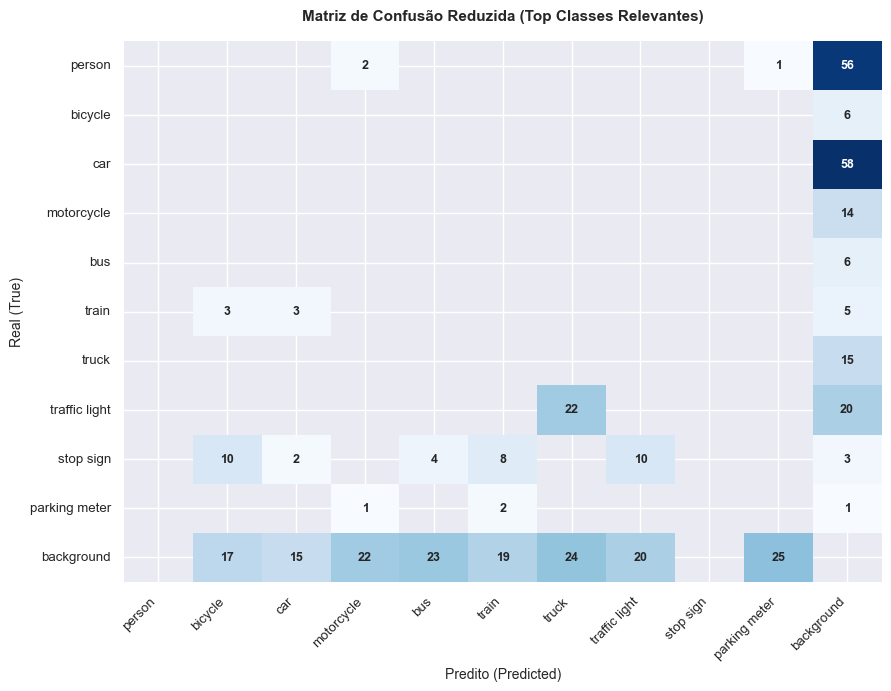


2. VERSÃO COMPLETA (Gráfico nativo gerado pelo YOLO com todo o mapeamento):


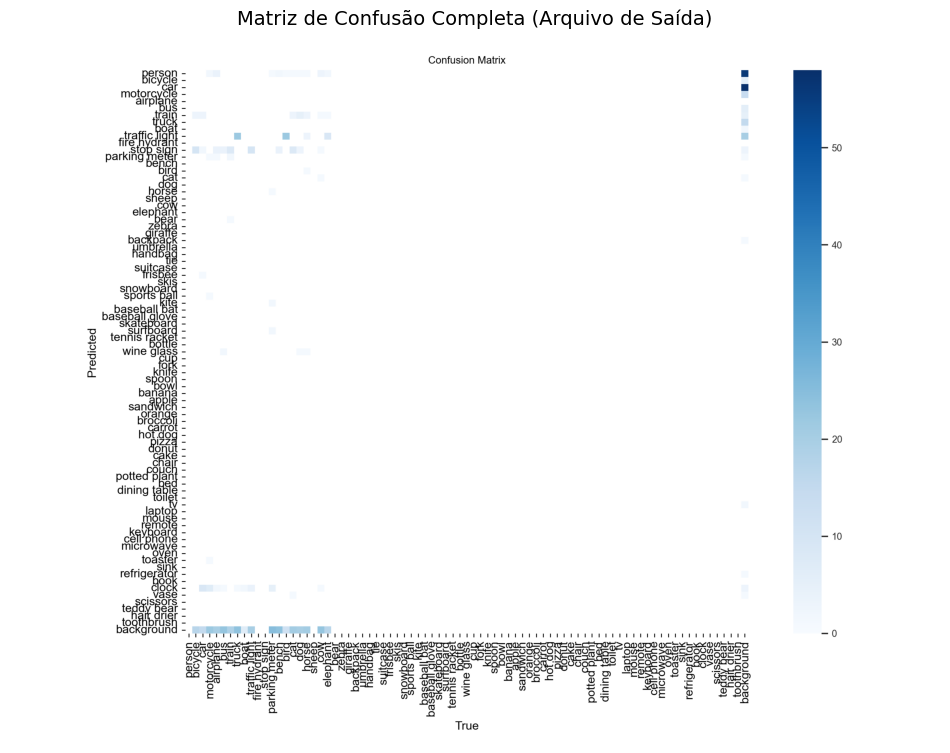

In [4]:
import pandas as pd
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

# Garante o patch do NumPy caso as células sejam rodadas fora de ordem
if not hasattr(np, "trapz") and hasattr(np, "trapezoid"):
    np.trapz = np.trapezoid

# Define o dispositivo seguro para validação pesada gráfica
DISPOSITIVO_VALIDACAO = 'cpu' if EH_AMD else DISPOSITIVO_TESTE

print(f"Processando todas as classes via {DISPOSITIVO_VALIDACAO} para gerar o relatório final...")

# Executa novamente habilitando a geração dos gráficos visuais (plots=True)
if EH_AMD:
    from ultralytics import YOLO
    model_val = YOLO(MODELO_PATH.replace(".onnx", ".pt") if MODELO_PATH.endswith(".onnx") else MODELO_PATH)
    metrics_globais = model_val.val(data=ARQUIVO_CONFIG, split="val", plots=True, device=DISPOSITIVO_VALIDACAO)
else:
    metrics_globais = model.val(data=ARQUIVO_CONFIG, split="val", plots=True, device=DISPOSITIVO_VALIDACAO)

# 1. Constrói o Classification Report estruturado em tabela a partir do mapeamento dinâmico
mapeamento_validacao = metrics_globais.names
classes_mapeadas = [mapeamento_validacao[i] for i in range(len(metrics_globais.box.p))]

# Tratamento dinâmico para extrair mAP50 e mAP50-95 sem estourar erros de tipos do NumPy
lista_ap50_global = metrics_globais.box.ap50() if callable(getattr(metrics_globais.box, "ap50", None)) else metrics_globais.box.ap50
lista_ap_global = metrics_globais.box.ap() if callable(getattr(metrics_globais.box, "ap", None)) else metrics_globais.box.ap

report_data = {
    "Classe": classes_mapeadas,
    "Precisão (Precision)": [float(p) for p in metrics_globais.box.p],
    "Revocação (Recall)": [float(r) for r in metrics_globais.box.r],
    "mAP50": [float(m) for m in lista_ap50_global],
    "mAP50-95": [float(m) for m in lista_ap_global]
}

df_report = pd.DataFrame(report_data)

# Adiciona a linha de média global (Macro Average)
linha_media = pd.DataFrame([{
    "Classe": "MÉDIA GLOBAL (all)",
    "Precisão (Precision)": float(metrics_globais.box.mp),
    "Revocação (Recall)": float(metrics_globais.box.mr),
    "mAP50": float(metrics_globais.box.map50),
    "mAP50-95": float(metrics_globais.box.map)
}])
df_report = pd.concat([df_report, linha_media], ignore_index=True)

# Exibe o relatório tabular estilizado
pd.set_option('display.float_format', lambda x: '%.4f' % x)
print("\n======================= CLASSIFICATION REPORT (YOLO) =======================")
display(df_report)


# ==============================================================================
# 2. SEÇÃO DE VISUALIZAÇÃO GRÁFICA: MATRIZES DE CONFUSÃO (COMPLETA E REDUZIDA)
# ==============================================================================
print("\n======================= ANÁLISE GRÁFICA DA MATRIZ DE CONFUSÃO =======================")

if hasattr(metrics_globais, 'confusion_matrix') and metrics_globais.confusion_matrix is not None:
    try:
        # PAINEL DE CONTROLE DO DESIGN E FILTRO DE CLASSES
        TAMANHO_LARGURA = 9        
        TAMANHO_ALTURA = 7         
        TAMANHO_FONTE_LABELS = 9.5   
        TAMANHO_FONTE_NUMEROS = 9.0  
        ESCONDER_ZEROS = True     
        
        # FILTROS DE ESCOPO BASE (Nível 1)
        FILTRAR_APENAS_CLASSES_DO_YAML = True
        FILTRAR_POR_LISTA_MANUAL = False
        CLASSES_DESEJADAS_MANUAL = ["do_not_enter", "stop", "bus_stop"]
        
        # LIMITADOR DE CLASSES MAIS RELEVANTES (Nível 2)
        LIMITAR_MAX_CLASSES = True       
        MAX_CLASSES_RELEVANTES = 10      
        
        # Coleta a matriz matemática bruta da validação
        matriz_bruta = metrics_globais.confusion_matrix.matrix
        mapeamento_real = {int(k): str(v) for k, v in mapeamento_validacao.items()}
        
        # Identifica a posição padrão da classe background
        idx_background = matriz_bruta.shape[0] - 1
        mapeamento_real[idx_background] = 'background'
            
        # Define o escopo inicial de strings permitidas
        strings_permitidas = []
        if FILTRAR_POR_LISTA_MANUAL:
            strings_permitidas = list(CLASSES_DESEJADAS_MANUAL)
        elif FILTRAR_APENAS_CLASSES_DO_YAML:
            strings_permitidas = list(NOMES_CLASSES_DINAMICO.values())
            
        # Sempre adicionamos o background temporariamente para a triagem
        if len(strings_permitidas) > 0 and 'background' not in strings_permitidas:
            strings_permitidas.append('background')
                
        # Filtra os índices que pertencem ao escopo base
        indices_escopo = []
        for idx, nome in mapeamento_real.items():
            if len(strings_permitidas) > 0:
                if nome in strings_permitidas:
                    indices_escopo.append(idx)
            else:
                if matriz_bruta[idx, :].sum() > 0 or matriz_bruta[:, idx].sum() > 0:
                    indices_escopo.append(idx)
                    
        if len(indices_escopo) > 0:
            if LIMITAR_MAX_CLASSES and len(indices_escopo) > MAX_CLASSES_RELEVANTES:
                volumes = {}
                for idx in indices_escopo:
                    if idx == idx_background:
                        continue 
                    volumes[idx] = matriz_bruta[idx, :].sum() + matriz_bruta[:, idx].sum()
                
                ids_mais_relevantes = sorted(volumes, key=volumes.get, reverse=True)[:MAX_CLASSES_RELEVANTES]
                
                if idx_background in indices_escopo:
                    ids_mais_relevantes.append(idx_background)
                
                indices_filtrados = [idx for idx in sorted(indices_escopo) if idx in ids_mais_relevantes]
            else:
                indices_filtrados = sorted(indices_escopo)
            
            nomes_reduzidos = [mapeamento_real[idx] for idx in indices_filtrados]
            matriz_reduzida = matriz_bruta[np.ix_(indices_filtrados, indices_filtrados)]
            dados_plotagem = matriz_reduzida.astype(float)
            mascara = (dados_plotagem == 0) if ESCONDER_ZEROS else None
            
            print(f"\n1. VERSÃO REDUZIDA (Exibindo estritamente as {len(nomes_reduzidos)} classes mais relevantes):")
            
            sns.set_theme(rc={'font.size': TAMANHO_FONTE_LABELS})
            
            # REMOVIDO ATRIBUIÇÃO DE VARIÁVEL (Chama direto o plot do matplotlib)
            plt.figure(figsize=(TAMANHO_LARGURA, TAMANHO_ALTURA))
            
            sns.heatmap(
                dados_plotagem, 
                annot=True, 
                fmt='.0f', 
                cmap='Blues', 
                xticklabels=nomes_reduzidos, 
                yticklabels=nomes_reduzidos,
                mask=mascara, 
                cbar=False,
                annot_kws={"size": TAMANHO_FONTE_NUMEROS, "weight": "bold"}
            )
            
            plt.title('Matriz de Confusão Reduzida (Top Classes Relevantes)', fontsize=11, pad=15, fontweight='bold')
            plt.xlabel('Predito (Predicted)', fontsize=10)
            plt.ylabel('Real (True)', fontsize=10)
            plt.xticks(rotation=45, ha='right', fontsize=TAMANHO_FONTE_LABELS)
            plt.yticks(rotation=0, fontsize=TAMANHO_FONTE_LABELS)
            plt.tight_layout()
            plt.show()
            
            sns.reset_orig()
        else:
            print("Nota: Nenhuma classe foi localizada para gerar a matriz reduzida.")
            
    except Exception as e:
        print(f"Nota: Erro ao renderizar o gráfico filtrado via seaborn. Motivo: {e}")

# Gráfico 2: Exibição da Imagem Original Padrão do YOLO
caminho_matriz = os.path.join(metrics_globais.save_dir, "confusion_matrix.png")
if os.path.exists(caminho_matriz):
    print("\n2. VERSÃO COMPLETA (Gráfico nativo gerado pelo YOLO com todo o mapeamento):")
    matriz_img = cv2.imread(caminho_matriz)
    matriz_rgb = cv2.cvtColor(matriz_img, cv2.COLOR_BGR2RGB)
    
    # REMOVIDO ATRIBUIÇÃO DE VARIÁVEL
    plt.figure(figsize=(12, 10))
    plt.imshow(matriz_rgb)
    plt.axis('off')
    plt.title('Matriz de Confusão Completa (Arquivo de Saída)', fontsize=14, pad=15)
    plt.show()
    
    # Limpa referências ocultas da memória
    plt.close('all')
else:
    print(f"Aviso: O gráfico da matriz de confusão nativa não foi encontrado em: {caminho_matriz}")